# 4 · Walk-forward backtest of allocation methods
Each strategy is re-estimated **monthly** on a rolling 2-year window and held until the next rebalance, with 5 bp transaction costs on turnover. No look-ahead: weights at each rebalance date use only data available on that date.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
prices = pd.read_csv("../data/prices.csv", index_col=0, parse_dates=True)   # refresh: python scripts/fetch_prices.py
bench = prices.pop("SPY")
rets = np.log(prices).diff().dropna()
RF = 0.025  # average T-bill rate over the sample (approx.)
from portopt import backtest, black_litterman as bl, covariance, kelly, optimize

In [2]:
simple = prices.pct_change().dropna()

def denoised(h):
    return covariance.denoise(covariance.sample(h), len(h))[0]

strategies = {
    "Equal weight": lambda h: optimize.equal_weight(h.cov()),
    "Min variance (sample)": lambda h: optimize.min_variance(covariance.sample(h)),
    "Min variance (denoised)": lambda h: optimize.min_variance(denoised(h)),
    "Max Sharpe (shrunk mu)": lambda h: optimize.max_sharpe(0.5 * h.mean() * 252 + 0.5 * (h.mean() * 252).mean(),
                                                            covariance.ledoit_wolf(h), RF, max_weight=0.3),
    "Risk parity": lambda h: optimize.risk_parity(covariance.ledoit_wolf(h)),
    "HRP (denoised)": lambda h: optimize.hrp(denoised(h)),
    "Half Kelly, long-only, 1x cap": lambda h: kelly.kelly_weights(0.5 * h.mean() * 252 + 0.5 * (h.mean() * 252).mean(),
                                                     covariance.ledoit_wolf(h), RF, fraction=0.5, long_only=True, max_leverage=1.0),
}
results = {name: backtest.walk_forward(simple, f, lookback=504, cost_bps=5, cash_rate=RF) for name, f in strategies.items()}
spy = bench.pct_change().reindex(results["Equal weight"].index)
results["SPY (benchmark)"] = pd.DataFrame({"ret": spy, "turnover": 0.0})
table = backtest.summary(results, rf=RF)
table.style.format({"CAGR": "{:.1%}", "Volatility": "{:.1%}", "Sharpe": "{:.2f}", "Sortino": "{:.2f}",
                    "Max drawdown": "{:.1%}", "Calmar": "{:.2f}", "Avg turnover / rebalance": "{:.1%}"}, na_rep="-")

,CAGR,Volatility,Sharpe,Sortino,Max drawdown,Calmar,Avg turnover / rebalance
Equal weight,19.8%,17.4%,0.98,1.20,-35.9%,0.55,5.1%
Min variance (sample),10.2%,14.5%,0.57,0.72,-33.6%,0.30,10.2%
Min variance (denoised),10.1%,14.6%,0.56,0.70,-35.1%,0.29,9.5%
Max Sharpe (shrunk mu),20.2%,17.8%,0.98,1.30,-29.3%,0.69,27.3%
Risk parity,16.8%,16.0%,0.90,1.10,-34.8%,0.48,5.0%
HRP (denoised),14.9%,15.3%,0.82,0.99,-35.4%,0.42,12.1%
"Half Kelly, long-only, 1x cap",20.8%,17.6%,1.02,1.31,-32.6%,0.64,26.3%
SPY (benchmark),13.9%,17.2%,0.70,0.86,-33.7%,0.41,-


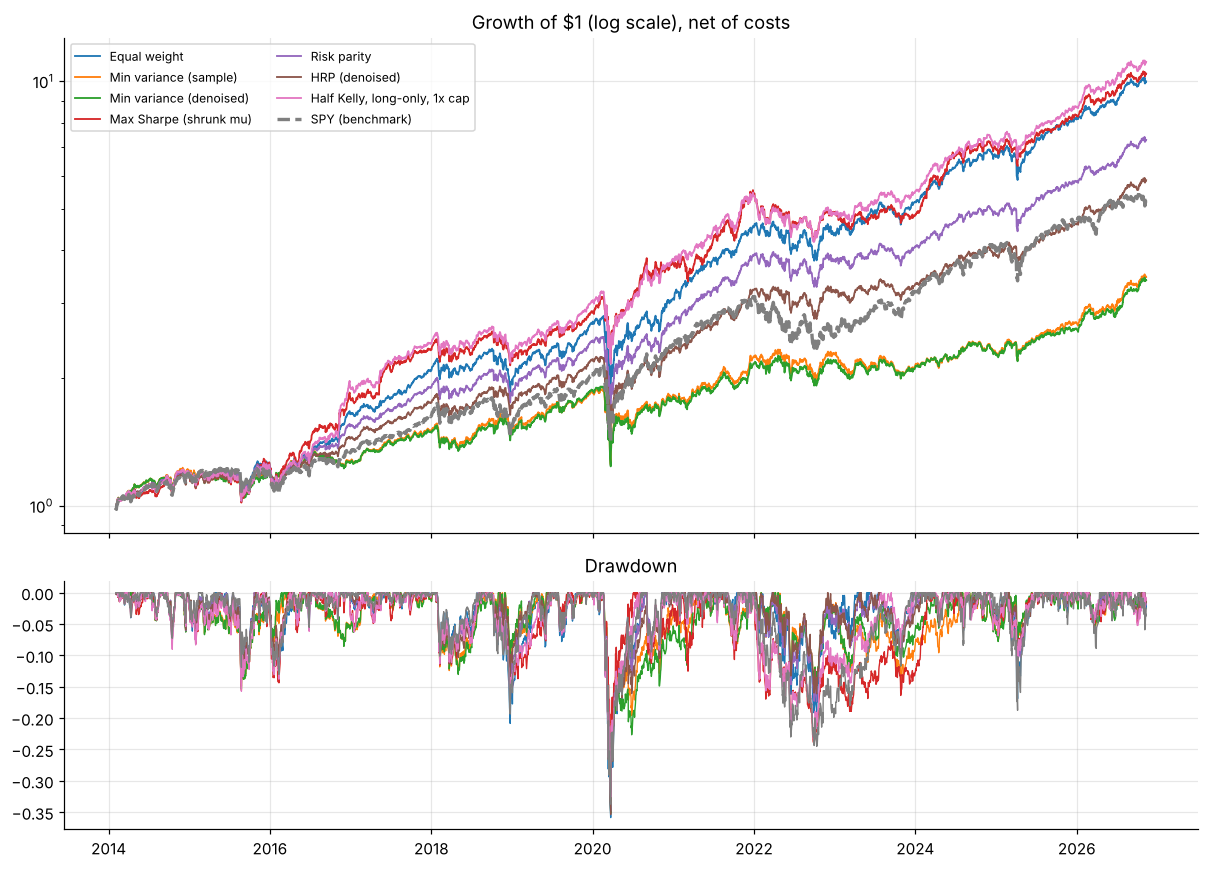

In [3]:
wealth = pd.DataFrame({k: (1 + v["ret"]).cumprod() for k, v in results.items()})
fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for c in wealth:
    ax[0].plot(wealth.index, wealth[c], lw=2.2 if "SPY" in c else 1.2, ls="--" if "SPY" in c else "-", label=c)
    ax[1].plot(wealth.index, wealth[c] / wealth[c].cummax() - 1, lw=0.9)
ax[0].set_yscale("log"); ax[0].set_title("Growth of $1 (log scale), net of costs"); ax[0].legend(fontsize=8, ncol=2)
ax[1].set_title("Drawdown"); fig.tight_layout()
plt.savefig(IMG / "backtest_equity_curves.png", bbox_inches="tight"); plt.show()

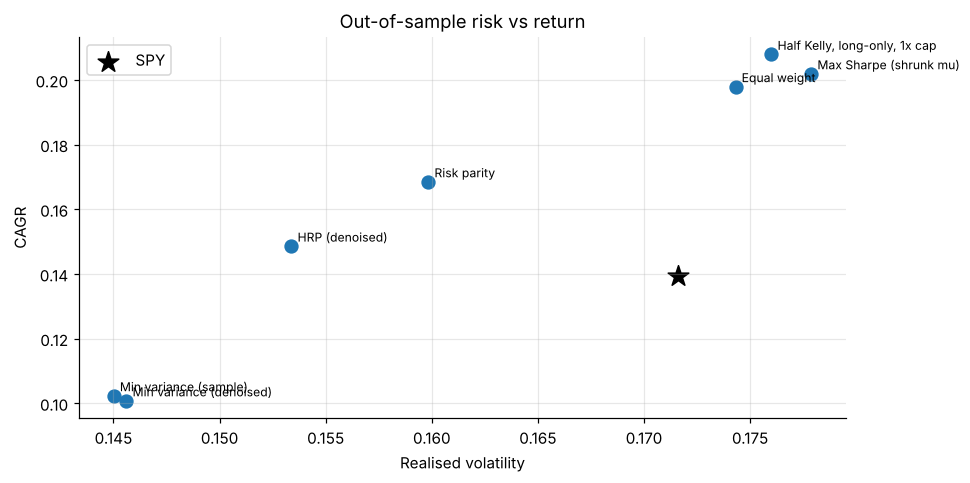

In [4]:
t = table.drop("SPY (benchmark)")
plt.scatter(t.Volatility, t.CAGR, s=70)
for n, row in t.iterrows(): plt.annotate(n, (row.Volatility, row.CAGR), fontsize=8, xytext=(4, 3), textcoords="offset points")
b = table.loc["SPY (benchmark)"]; plt.scatter(b.Volatility, b.CAGR, marker="*", s=200, c="k", label="SPY")
plt.xlabel("Realised volatility"); plt.ylabel("CAGR"); plt.title("Out-of-sample risk vs return"); plt.legend()
plt.savefig(IMG / "backtest_risk_return.png", bbox_inches="tight"); plt.show()

### Reading the results
* **Risk-based methods** (min-variance, risk parity, HRP) cut realised volatility compared with equal weight. They don't escape market-wide crashes, though: the 2020 drawdown is similar for all long-only portfolios. Min-variance trades the lowest risk for the lowest return in a decade when growth stocks led.
* **Denoising** gives a small reduction in min-variance turnover at similar risk.
* **Return-aware methods** (shrunk max-Sharpe, capped half-Kelly) did best here. They have much higher turnover, and their edge depends on return estimates staying informative, which is fragile.
* Results come from one 12-stock universe and one historical path, so treat them as a demonstration of the framework, not a recommendation.